# 06c — KPIs de impacto (IL5) en lenguaje de negocio

**Capa 7 — KPIs** · Complementa los notebooks 06 y 06b

**Objetivo:** traducir los resultados del backtest y del historial del semáforo a cifras que el comité entiende sin saber estadística: **dólares**, **decisiones por año** y **horas de trabajo**.

Cada KPI lleva una etiqueta que dice de dónde sale su valor:

| Etiqueta | Significado |
|---|---|
| **MEDIDO** | Calculado con datos o logs reales del producto |
| **DEFINIDO** | Meta y forma de medición fijadas; todavía no hay datos |
| **PROYECTADO** | Calculado con supuestos (parámetros marcados `SUPUESTO` en `src/config.py`) |

**Advertencia que acompaña a todo este notebook:** la regla v2 **no está validada fuera de muestra**. El criterio fijado antes de evaluarla se cumple en 1 de 2 episodios evaluables (Bitcoin sí; Nikkei no), y 1 de 2 no es mayoría. Por eso, la pérdida evitada en US$ es una **proyección ilustrativa**, no una promesa de resultado. El IL5 principal del producto sigue siendo la **calidad de detección** (notebooks 03b y 06b).

**Entradas:**
- `outputs/resumen_episodios_v1_v2.csv` (tabla de episodios del notebook 06b, cifras verificadas en `docs/auditoria.md`).
- `data/processed/panel_semanal.csv` (semáforo histórico).
- `logs/radar_*.log` (duración real de `main.py`).
- Supuestos de `src/config.py`.

**Salidas:** tablas de KPIs y figuras en `outputs/figuras/`. Las funciones están en `src/kpis.py`.

In [1]:
import sys
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src import config as C
from src import kpis as K

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": "#52514e",
    "xtick.color": "#898781", "ytick.color": "#898781",
    "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False,
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
})
pd.set_option("display.width", 200)
AZUL, GRIS, TINTA = "#2a78d6", "#898781", "#52514e"
DIR_FIGURAS = C.DIR_OUTPUTS / "figuras"
DIR_FIGURAS.mkdir(exist_ok=True)
millones = lambda v: f"US$ {v / 1e6:,.1f} M".replace(",", "X").replace(".", ",").replace("X", ".")

print("Supuestos (src/config.py):")
print(f"  EXPOSICION_USD        = {C.EXPOSICION_USD:,.0f}".replace(",", "."))
print(f"  HORAS_ANALISIS_SEMANA = {C.HORAS_ANALISIS_SEMANA}")
print(f"  Sensibilidad          = {[millones(e) for e in C.EXPOSICIONES_SENSIBILIDAD_USD]}")

Supuestos (src/config.py):
  EXPOSICION_USD        = 100.000.000
  HORAS_ANALISIS_SEMANA = 4
  Sensibilidad          = ['US$ 50,0 M', 'US$ 100,0 M', 'US$ 500,0 M']


## 1. Pérdida evitada en US$ (PROYECTADO)

**Pregunta de negocio:** si el comité hubiera seguido la regla v2 (rojo → 50% invertido, con un año de "enfriamiento" después del rojo), ¿cuánto menos habría perdido en el peor momento de cada burbuja?

**Cálculo:**

$$\text{pérdida evitada} = (\text{caída máx. mantener} - \text{caída máx. v2}) \times \text{EXPOSICION\_USD}$$

con las caídas como magnitudes positivas. Por ejemplo, si mantener cae 77% y la v2 cae 65%, se evitan 12 puntos porcentuales: US$12 millones sobre US$100 millones.

**Supuestos y límites:**
- **EXPOSICION_USD = US$100 millones es un SUPUESTO** (orden de magnitud de una posición temática; el usuario es hipotético).
- La caída máxima es de **cada estrategia desde su propio máximo**. Llevarla a dólares supone que la exposición vale US$100 millones al inicio de la caída.
- Son caídas de un índice, sin dividendos y con la caja al 0%, igual que en el backtest.
- Al lado se muestra el **percentil placebo** (qué tan bien le fue a la regla frente a 1.000 reglas que reducen exposición al azar; bajo es mejor, el criterio exigía < 20) y si el episodio está **dentro** de la muestra usada para diseñar la regla o **fuera** de ella.

In [2]:
perdida = K.perdida_evitada()
vista = pd.DataFrame({
    "Muestra": perdida["muestra"],
    "Rojo antes del peak (sem.)": perdida["anticipacion_rojo_semanas"],
    "Caída máx. mantener": perdida["caida_mantener"].map("{:.1%}".format),
    "Caída máx. v2": perdida["caida_v2"].map("{:.1%}".format),
    "Puntos evitados": perdida["puntos_evitados"].map(lambda v: f"{100 * v:.1f} pp"),
    "Pérdida evitada": perdida["perdida_evitada_usd"].map(millones),
    "Percentil placebo v2": perdida["percentil_placebo_v2"],
    "Supera al azar (< 20)": perdida["supera_al_azar"].map({True: "Sí", False: "No"}),
    "Etiqueta": perdida["etiqueta"],
})
vista

,Muestra,Rojo antes del peak (sem.),Caída máx. mantener,Caída máx. v2,Puntos evitados,Pérdida evitada,Percentil placebo v2,Supera al azar (< 20),Etiqueta
episodio,,,,,,,,,
Nasdaq 2000-2002,dentro de muestra,11,-77.4%,-64.8%,12.6 pp,"US$ 12,6 M",13.8,Sí,PROYECTADO
Nikkei 1989,fuera de muestra,45,-61.9%,-57.7%,4.2 pp,"US$ 4,2 M",53.6,No,PROYECTADO
Bitcoin 2021,fuera de muestra,42,-74.2%,-53.5%,20.7 pp,"US$ 20,7 M",13.2,Sí,PROYECTADO


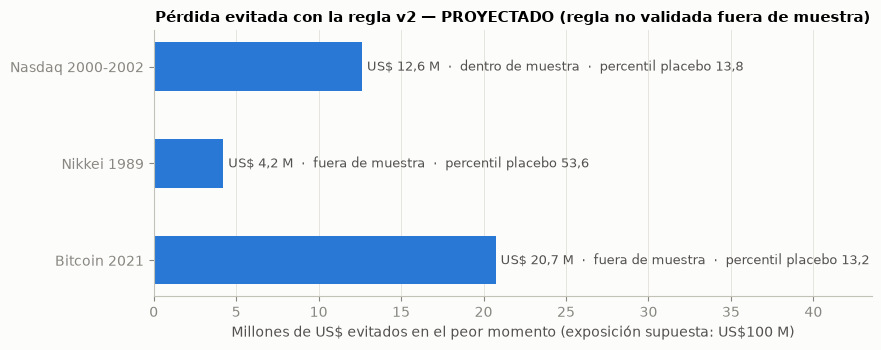

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.6))
y = range(len(perdida))[::-1]
ax.barh(list(y), perdida["perdida_evitada_usd"] / 1e6, height=0.5, color=AZUL)
for yi, (episodio, fila) in zip(y, perdida.iterrows()):
    ax.text(fila["perdida_evitada_usd"] / 1e6 + 0.3, yi,
            f"{millones(fila['perdida_evitada_usd'])}  ·  {fila['muestra']}  ·  percentil placebo "
            f"{fila['percentil_placebo_v2']:.1f}".replace(".", ",", 1), va="center", fontsize=9, color=TINTA)
ax.set_yticks(list(y), perdida.index)
ax.set_xlim(0, perdida["perdida_evitada_usd"].max() / 1e6 * 2.1)
ax.set_xlabel(r"Millones de US\$ evitados en el peor momento (exposición supuesta: US\$100 M)")
ax.set_title("Pérdida evitada con la regla v2 — PROYECTADO (regla no validada fuera de muestra)")
ax.grid(axis="y", visible=False)
ax.set_axisbelow(True)
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "perdida_evitada_usd.png", dpi=150, bbox_inches="tight")
plt.show()

**Cómo leerlo:**
- **Nasdaq 2000-2002:** US$12,6 millones evitados, pero está **dentro de muestra**: la regla v2 se diseñó mirando este episodio, así que no cuenta como evidencia.
- **Bitcoin 2021 (fuera de muestra):** el monto mayor, US$20,7 millones, y además supera al azar (percentil 13,2 < 20).
- **Nikkei 1989 (fuera de muestra):** la v2 redujo la caída, solo US$4,2 millones, y **no supera al azar** (percentil 53,6): reducir exposición en fechas aleatorias habría protegido lo mismo.
- No se suman los episodios: son burbujas distintas en mercados distintos, y el resultado no se puede extrapolar.

### Sensibilidad a la exposición

La pérdida evitada es proporcional a la exposición supuesta: con US$500 millones, cada cifra se multiplica por 5. Lo que **no** cambia con la exposición es si la regla supera al azar.

In [4]:
sensibilidad = pd.DataFrame({
    millones(e): K.perdida_evitada(exposicion=e)["perdida_evitada_usd"].map(millones)
    for e in C.EXPOSICIONES_SENSIBILIDAD_USD
})
sensibilidad.columns = [f"Exposición {c}" for c in sensibilidad.columns]
sensibilidad["Percentil placebo v2"] = perdida["percentil_placebo_v2"]
sensibilidad

,"Exposición US$ 50,0 M","Exposición US$ 100,0 M","Exposición US$ 500,0 M",Percentil placebo v2
episodio,,,,
Nasdaq 2000-2002,"US$ 6,3 M","US$ 12,6 M","US$ 63,1 M",13.8
Nikkei 1989,"US$ 2,1 M","US$ 4,2 M","US$ 21,1 M",53.6
Bitcoin 2021,"US$ 10,4 M","US$ 20,7 M","US$ 103,7 M",13.2


## 2. Decisiones habilitadas por año (MEDIDO en el historial)

**Pregunta de negocio:** ¿cuántas veces al año el radar habría llevado al comité a discutir reducir o cubrir una posición?

**Cálculo:** número de **episodios rojos** (semáforo con persistencia de 6 semanas) que empiezan en cada año calendario, en el historial del producto (`panel_semanal.csv`). Un episodio rojo es una decisión que el comité debe tomar: mantener, reducir o cubrir. Se cuenta desde la primera semana con semáforo (diciembre de 1999, porque el BSADF necesita 5 años de historia y los datos parten en 1995).

**Límites:**
- El universo no está completo en todo el periodo. GOOGL, AVGO y META tienen semáforo recién 5 años después de salir a bolsa (2009, 2014 y 2017).
- Aquí el Nasdaq usa los datos del producto, desde 1995. En el backtest se usa su historia desde 1990, que adelanta su rojo de la puntocom.

In [5]:
panel = pd.read_csv(C.DIR_PROCESSED / "panel_semanal.csv", parse_dates=["fecha"])
resumen_dec, por_ano = K.decisiones_habilitadas(panel)
(resumen_dec.set_index("grupo")
 .assign(anos=lambda d: d["anos"].round(1), por_ano=lambda d: d["por_ano"].round(2))
 .rename(columns={"desde": "Desde", "hasta": "Hasta", "anos": "Años", "episodios_rojos": "Episodios rojos",
                  "por_ano": "Decisiones por año", "max_en_un_ano": "Máximo en un año",
                  "anos_sin_rojo": "Años calendario sin rojo", "etiqueta": "Etiqueta"}))

,Desde,Hasta,Años,Episodios rojos,Decisiones por año,Máximo en un año,Años calendario sin rojo,Etiqueta
grupo,,,,,,,,
Universo (9 acciones),1999-12-24,2026-10-30,26.9,30,1.12,5,11,MEDIDO
Nasdaq (^IXIC),1999-12-24,2026-10-30,26.9,1,0.04,1,27,MEDIDO


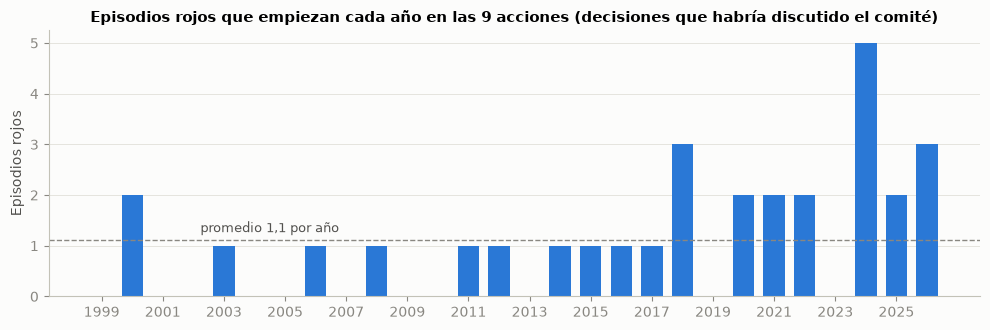

fecha,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,...,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
Universo (9 acciones),0,2,0,0,1,0,0,1,0,1,...,1,3,0,2,2,2,0,5,2,3
Nasdaq (^IXIC),0,1,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [6]:
universo = por_ano["Universo (9 acciones)"]
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.bar(universo.index, universo, width=0.7, color=AZUL)
ax.set_title("Episodios rojos que empiezan cada año en las 9 acciones (decisiones que habría discutido el comité)")
ax.set_ylabel("Episodios rojos")
ax.set_xticks(universo.index[::2])
ax.grid(axis="x", visible=False)
ax.set_axisbelow(True)
promedio = resumen_dec.set_index("grupo").loc["Universo (9 acciones)", "por_ano"]
ax.axhline(promedio, color=GRIS, lw=1, ls="--")
ax.text(2004.5, promedio + 0.15, f"promedio {promedio:.1f} por año".replace(".", ","), color=TINTA, fontsize=9,
        ha="center")
fig.tight_layout()
fig.savefig(DIR_FIGURAS / "decisiones_por_ano.png", dpi=150, bbox_inches="tight")
plt.show()
por_ano.T

**Cómo leerlo:**
- En las 9 acciones, el radar habría llevado al comité a discutir en promedio **algo más de una posición por año** (30 episodios en 26,9 años). En 11 de los 28 años calendario no hubo ninguna; 1999 tiene una sola semana con semáforo.
- Hasta 2017 hubo a lo sumo uno por año, salvo 2000 (AMD y ORCL). Los rojos se concentran en los años recientes: 2018 (3) y 2024-2026 (10 episodios, 5 de ellos en 2024), con el auge de la IA.
- En el Nasdaq, el rojo se encendió **una sola vez en 27 años**, en la puntocom (2000). Para el índice completo es una alerta rara.

La carga de trabajo para el comité es baja: el semáforo filtra y deja para discusión solo los casos de crecimiento explosivo sostenido.

## 3. Eficiencia operativa (PROYECTADO)

**Pregunta de negocio:** ¿cuánto trabajo manual reemplaza el radar?

**Cálculo:**
- **Sin el radar:** `HORAS_ANALISIS_SEMANA` × 52 semanas = horas al año de descargar precios, actualizar planillas y revisar gráficos. **4 horas por semana es un SUPUESTO**, no una medición.
- **Con el radar:** duración real de `main.py` × 52. Se usa la corrida más lenta medida con descarga de datos, que es **MEDIDA** en los logs.

**Límite:** el radar reemplaza la preparación, no la discusión. El tiempo del comité para leer el reporte y decidir no se cuenta (hoy queda DEFINIDO en el KPI IL4 de frecuencia de uso).

In [7]:
ef = K.eficiencia_operativa()
pd.DataFrame({
    "Valor": [f"{ef['horas_manual_ano']:.0f} h/año", f"{ef['duracion_corrida_s']:.1f} s por corrida",
              f"{ef['horas_radar_ano'] * 60:.1f} min/año", f"{ef['horas_liberadas_ano']:.0f} h/año"],
    "Origen": ["SUPUESTO (4 h × 52)", "MEDIDO (logs, corrida con descarga)", "MEDIDO × 52", "PROYECTADO"],
}, index=["Análisis manual reemplazado", "Duración de main.py", "Tiempo de máquina del radar", "Horas liberadas"])

,Valor,Origen
Análisis manual reemplazado,208 h/año,SUPUESTO (4 h × 52)
Duración de main.py,14.6 s por corrida,"MEDIDO (logs, corrida con descarga)"
Tiempo de máquina del radar,12.7 min/año,MEDIDO × 52
Horas liberadas,208 h/año,PROYECTADO


## 4. Resumen de los KPIs IL5 para la presentación

In [8]:
fuera = perdida[perdida["muestra"] == "fuera de muestra"]
dec = resumen_dec.set_index("grupo")
pd.DataFrame([
    {"KPI": "Anticipación del rojo antes del peak", "Valor": "Puntocom 11 sem. · Nikkei 45 · Bitcoin 42",
     "Etiqueta": K.MEDIDO, "Fuente": "Notebooks 03b y 06b"},
    {"KPI": "Pérdida evitada (v2, fuera de muestra)",
     "Valor": " · ".join(f"{e} {millones(v)}" for e, v in fuera["perdida_evitada_usd"].items()),
     "Etiqueta": K.PROYECTADO, "Fuente": "src/kpis.py · EXPOSICION_USD (SUPUESTO); regla no validada (1 de 2)"},
    {"KPI": "Decisiones habilitadas por año",
     "Valor": f"{dec.loc['Universo (9 acciones)', 'por_ano']:.1f} en las 9 acciones · "
              f"{dec.loc['Nasdaq (^IXIC)', 'episodios_rojos']} en {dec.loc['Nasdaq (^IXIC)', 'anos']:.0f} años en el Nasdaq",
     "Etiqueta": K.MEDIDO, "Fuente": "panel_semanal.csv"},
    {"KPI": "Horas de análisis liberadas", "Valor": f"{ef['horas_liberadas_ano']:.0f} h/año",
     "Etiqueta": K.PROYECTADO, "Fuente": "HORAS_ANALISIS_SEMANA (SUPUESTO) y logs"},
]).set_index("KPI")

,Valor,Etiqueta,Fuente
KPI,,,
Anticipación del rojo antes del peak,Puntocom 11 sem. · Nikkei 45 · Bitcoin 42,MEDIDO,Notebooks 03b y 06b
"Pérdida evitada (v2, fuera de muestra)","Nikkei 1989 US$ 4,2 M · Bitcoin 2021 US$ 20,7 M",PROYECTADO,src/kpis.py · EXPOSICION_USD (SUPUESTO); regla...
Decisiones habilitadas por año,1.1 en las 9 acciones · 1 en 27 años en el Nasdaq,MEDIDO,panel_semanal.csv
Horas de análisis liberadas,208 h/año,PROYECTADO,HORAS_ANALISIS_SEMANA (SUPUESTO) y logs


## Conclusión

- El valor **medido** del producto es la detección: el rojo llega antes del peak en las tres burbujas evaluadas y lleva al comité a discutir alrededor de una posición por año.
- Los dólares evitados son una **proyección** sobre una exposición supuesta y con una regla que **no** pasó su validación fuera de muestra. Sirven para dimensionar el orden de magnitud, no para prometer un resultado. Solo en Bitcoin la regla supera al azar.
- La eficiencia operativa es real en la preparación (segundos de máquina contra horas de planilla), pero su monto depende del supuesto de 4 horas semanales.